# Exercise 4: Transformers on Images + GLU-MLP Ablations (ViT × GLU Variants)

## In this exercise you will combine two influential ideas:

Vision Transformers (ViT) from “An Image is Worth 16×16 Words: Transformers for Image Recognition at Scale” (Dosovitskiy et al., 2020) https://arxiv.org/pdf/2010.11929:
ViT shows that you can treat an image like a sequence of tokens by splitting it into non-overlapping patches (e.g. 16×16 in the paper), embedding each patch into a vector, adding positional information, and then applying standard Transformer blocks for classification.

Gated MLPs (GLU variants) from “GLU Variants Improve Transformer” (Shazeer, 2020) https://arxiv.org/pdf/2002.05202:
Shazeer proposes replacing the standard Transformer feed-forward layer (FFN/MLP) with gated linear unit (GLU) variants such as GEGLU and SwiGLU, which often improves training dynamics and final performance under comparable compute/parameter budgets.

## What you will do

You will implement a tiny ViT-style classifier for MNIST, then run a controlled ablation where you replace the MLP inside each Transformer block:

Baseline FFN (GELU):
Linear(d_model → d_ff) → GELU → Linear(d_ff → d_model)

GLU-family MLPs (choose at least two and justify):

GEGLU, SwiGLU, other activation functions

Your goal is to evaluate whether these GLU variants change:

- convergence speed (loss vs steps),

- final test accuracy,

- and/or stability across runs.

## Key ViT concepts you will implement

- To convert MNIST images into Transformer tokens, you will:
  Patchify each 28×28 image into non-overlapping P×P patches.
  If P=4, then you get a 7×7 patch grid → 49 tokens per image.

- Embed patches with a linear layer: patch vectors → d_model.

- Add positional embeddings so the model knows where each patch came from.

- Apply n_layers Transformer encoder blocks.

- Pool token features (e.g., mean pooling) and project to 10 classes.

## Key GLU concept you will implement

GLU-style MLPs replace a standard FFN with a gating mechanism:
compute two projections a and b, apply a nonlinearity to a (variant-dependent), multiply elementwise: act(a) * b, project back to d_model.
To keep the comparison fair, use the 2/3 width rule from Shazeer.

What we provide vs what you implement

### We provide:

- MNIST loading + dataloaders

- a minimal training loop structure (AdamW)

- a suggested small model configuration that runs on CPU

### You implement:

- patch tokenization (patchify)

- patch embedding + positional embedding strategy

- a pre-LN Transformer encoder block using nn.MultiheadAttention

- at least two GLU MLP variants + one FFN baseline

- metric logging sufficient to support your conclusion

## Deliverables

Run at least 3 variants (baseline + the activation functions you choose for GLU) and report:

- final and best test accuracy

- number of trainable parameters

- a plot or printed summary of loss/accuracy over epochs

- a short discussion of your results

In [1]:
from __future__ import annotations

import math
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [2]:
def patchify(x: torch.Tensor, patch_size: int) -> torch.Tensor:
    """Convert images to patch tokens.
    Shape x: (B, C, H, W) -> (B, num_patches, patch_dim)
    """
    B, C, H, W = x.shape
    ph = pw = patch_size
    assert H % ph == 0 and W % pw == 0, "Image dimensions must be divisible by patch_size"
    
    # Unfold into non-overlapping patches
    x = x.unfold(2, ph, ph).unfold(3, pw, pw) # (B, C, H/ph, W/pw, ph, pw)
    x = x.permute(0, 2, 3, 1, 4, 5)          # (B, H/ph, W/pw, C, ph, pw)
    num_patches = (H // ph) * (W // pw)
    patch_dim = C * ph * pw
    return x.reshape(B, num_patches, patch_dim)

In [3]:
# TODO: Add positional encoding as done in the ViT paper and patch projection
class PatchEmbed(nn.Module):
    def __init__(self, patch_dim: int, d_model: int):
        super().__init__()
        self.proj = nn.Linear(patch_dim, d_model)

    def forward(self, x_patches: torch.Tensor) -> torch.Tensor:
        return self.proj(x_patches)


class PositionalEmbedding(nn.Module):
    def __init__(self, num_tokens: int, d_model: int):
        super().__init__()
        self.pos_emb = nn.Parameter(torch.randn(1, num_tokens, d_model) * 0.02)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.pos_emb

In [4]:
# TODO: Define the variants you want to compare against each other from the GLU paper. Justify your choice.
class FeedForward(nn.Module):
    """
    Standard Transformer FFN:
      x -> Linear(d_model->d_ff) -> GELU -> Dropout -> Linear(d_ff->d_model) -> Dropout
    """
    def __init__(self, d_model: int, d_ff: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class GLUFeedForward(nn.Module):
    """GLU-family FFN"""
    def __init__(self, d_model: int, d_ff_gated: int, dropout: float, variant: str):
        super().__init__()
        self.variant = variant.lower()
        # Gated linear units project to 2 * d_ff_gated (one half for gating, one for content)
        self.w1 = nn.Linear(d_model, d_ff_gated * 2)
        self.w2 = nn.Linear(d_ff_gated, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x12 = self.w1(x)
        x1, x2 = x12.chunk(2, dim=-1)
        
        if self.variant == "swiglu":
            gate = nn.functional.silu(x1)
        elif self.variant == "geglu":
            gate = nn.functional.gelu(x1)
        elif self.variant == "glu":
            gate = torch.sigmoid(x1)
        else:
            raise ValueError(f"Unknown GLU variant: {self.variant}")
            
        hidden = gate * x2
        return self.w2(self.dropout(hidden))

In [5]:
class TransformerEncoderBlock(nn.Module):
    """
    Pre-LN encoder block:
      x = x + Dropout(SelfAttn(LN(x)))
      x = x + Dropout(MLP(LN(x)))
    """
    def __init__(self, d_model: int, n_heads: int, mlp: nn.Module, dropout: float):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(embed_dim=d_model, num_heads=n_heads, dropout=dropout, batch_first=True)
        self.dropout1 = nn.Dropout(dropout)
        
        self.norm2 = nn.LayerNorm(d_model)
        self.mlp = mlp
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Self-attention sub-layer with residual connection
        norm_x1 = self.norm1(x)
        attn_out, _ = self.attn(norm_x1, norm_x1, norm_x1)
        x = x + self.dropout1(attn_out)
        
        # FFN/MLP sub-layer with residual connection
        x = x + self.dropout2(self.mlp(self.norm2(x)))
        return x

In [6]:
class TinyViT(nn.Module):
    """
    Tiny ViT-style classifier for MNIST.
    - patchify -> patch embed -> pos embed -> blocks -> mean pool -> head
    """
    def __init__(
        self,
        patch_size: int,
        d_model: int,
        n_heads: int,
        n_layers: int,
        d_ff: int,
        dropout: float,
        mlp_kind: str,
    ):
        super().__init__()
        assert 28 % patch_size == 0
        grid = 28 // patch_size
        self.num_tokens = grid * grid
        self.patch_size = patch_size
        patch_dim = patch_size * patch_size

        self.patch_embed = PatchEmbed(patch_dim, d_model)
        self.pos_embed = PositionalEmbedding(self.num_tokens, d_model)

        # Select MLP version based on experiment kind
        blocks = []
        for _ in range(n_layers):
            if mlp_kind == "standard":
                mlp = FeedForward(d_model=d_model, d_ff=d_ff, dropout=dropout)
            else:
                mlp = GLUFeedForward(d_model=d_model, d_ff_gated=d_ff, dropout=dropout, variant=mlp_kind)
            
            blocks.append(TransformerEncoderBlock(d_model=d_model, n_heads=n_heads, mlp=mlp, dropout=dropout))
            
        self.blocks = nn.ModuleList(blocks)
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, 10)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, 1, 28, 28)
        patches = patchify(x, patch_size=int((28 // int((self.num_tokens)**0.5))))
        x = self.patch_embed(patches)
        x = self.pos_embed(x)
        
        for block in self.blocks:
            x = block(x)
            
        x = self.norm(x)
        # Mean pooling across tokens
        x = x.mean(dim=1)
        return self.head(x)

In [7]:
@dataclass(frozen=True)
class TrainConfig:
    seed: int = 0
    batch_size: int = 128
    epochs: int = 3
    lr: float = 3e-4
    weight_decay: float = 0.01
    device: str = "cuda"  # set "cuda" if available

In [8]:
def train_one_run(
    mlp_kind: str,
    model: nn.Module,
    train_loader: DataLoader,
    test_loader: DataLoader,
    cfg: TrainConfig,
) -> dict:
    torch.manual_seed(cfg.seed)
    model.to(cfg.device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    
    train_losses = []
    test_accs = []
    
    for epoch in range(cfg.epochs):
        model.train()
        epoch_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(cfg.device), yb.to(cfg.device)
            opt.zero_grad()
            logits = model(xb)
            loss = nn.functional.cross_entropy(logits, yb)
            loss.backward()
            opt.step()
            epoch_loss += loss.item()
            train_losses.append(loss.item())
            
        # Evaluation loop
        model.eval()
        correct = 0.0
        total = 0.0
        with torch.no_grad():
            for xb, yb in test_loader:
                xb, yb = xb.to(cfg.device), yb.to(cfg.device)
                logits = model(xb)
                correct += (logits.argmax(dim=-1) == yb).float().sum().item()
                total += yb.numel()
                
        acc = correct / total
        test_accs.append(acc)
        print(f"[{mlp_kind}] Epoch {epoch+1}/{cfg.epochs} | Loss: {epoch_loss/len(train_loader):.4f} | Test Acc: {acc:.4f}")
        
    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    
    return {
        "mlp_kind": mlp_kind,
        "final_test_accuracy": test_accs[-1],
        "best_test_accuracy": max(test_accs),
        "num_trainable_parameters": num_params,
        "train_losses": train_losses,
        "test_accuracies": test_accs
    }


--- Running Experiment: standard ---
[standard] Epoch 1/3 | Loss: 1.1318 | Test Acc: 0.8385
[standard] Epoch 2/3 | Loss: 0.3910 | Test Acc: 0.9116
[standard] Epoch 3/3 | Loss: 0.2737 | Test Acc: 0.9315

--- Running Experiment: swiglu ---
[swiglu] Epoch 1/3 | Loss: 1.0507 | Test Acc: 0.8664
[swiglu] Epoch 2/3 | Loss: 0.3238 | Test Acc: 0.9316
[swiglu] Epoch 3/3 | Loss: 0.2049 | Test Acc: 0.9498

--- Running Experiment: geglu ---
[geglu] Epoch 1/3 | Loss: 1.0519 | Test Acc: 0.8979
[geglu] Epoch 2/3 | Loss: 0.2959 | Test Acc: 0.9400
[geglu] Epoch 3/3 | Loss: 0.1893 | Test Acc: 0.9544

EXPERIMENT DELIVERABLES REPORT
Variant (MLP Kind): STANDARD
  - Trainable Parameters: 104,970
  - Final Test Accuracy:  93.15%
  - Best Test Accuracy:   93.15%
--------------------------------------------------
Variant (MLP Kind): SWIGLU
  - Trainable Parameters: 138,250
  - Final Test Accuracy:  94.98%
  - Best Test Accuracy:   94.98%
--------------------------------------------------
Variant (MLP Kind): G

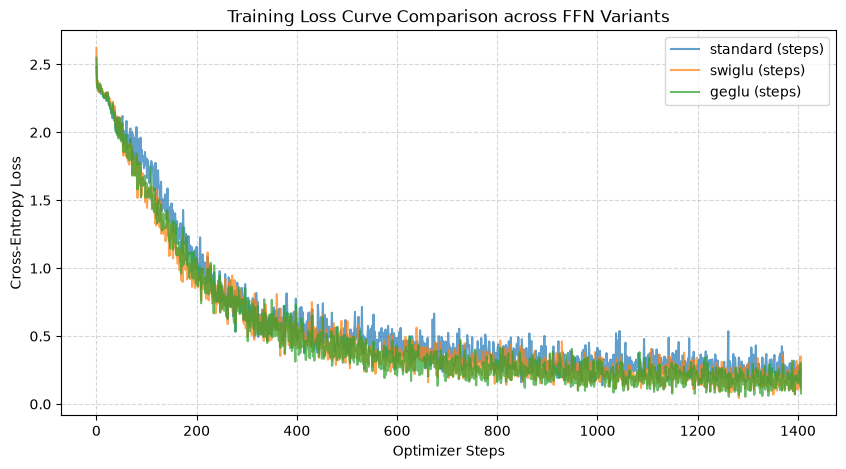

In [9]:
import matplotlib.pyplot as plt

cfg = TrainConfig(seed=0, batch_size=128, epochs=3, lr=3e-4, weight_decay=0.01, device="cpu")
tfm = transforms.Compose([transforms.ToTensor()])

train_ds = datasets.MNIST(root="./data", train=True, download=True, transform=tfm)
test_ds = datasets.MNIST(root="./data", train=False, download=True, transform=tfm)

train_loader = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=cfg.batch_size, shuffle=False, num_workers=0)

patch_size = 4
d_model = 64
n_heads = 4
n_layers = 2
d_ff = 256
dropout = 0.1

# Run baseline + GLU activation variants
runs = ["standard", "swiglu", "geglu"]
results = []

for kind in runs:
    model = TinyViT(
        patch_size=patch_size,
        d_model=d_model,
        n_heads=n_heads,
        n_layers=n_layers,
        d_ff=d_ff,
        dropout=dropout,
        mlp_kind=kind,
    )
    print(f"\n--- Running Experiment: {kind} ---")
    out = train_one_run(kind, model, train_loader, test_loader, cfg)
    results.append(out)

# --- Deliverables Report Summary ---
print("\n" + "="*50)
print("EXPERIMENT DELIVERABLES REPORT")
print("="*50)
for res in results:
    print(f"Variant (MLP Kind): {res['mlp_kind'].upper()}")
    print(f"  - Trainable Parameters: {res['num_trainable_parameters']:,}")
    print(f"  - Final Test Accuracy:  {res['final_test_accuracy']*100:.2f}%")
    print(f"  - Best Test Accuracy:   {res['best_test_accuracy']*100:.2f}%")
    print("-" * 50)

# --- Plotting Loss Curves ---
plt.figure(figsize=(10, 5))
for res in results:
    plt.plot(res["train_losses"], label=f"{res['mlp_kind']} (steps)", alpha=0.7)
plt.title("Training Loss Curve Comparison across FFN Variants")
plt.xlabel("Optimizer Steps")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# TinyViT Notebook Architecture & Execution Guide

## 1. Patchification and Embeddings
* **`patchify`**: Converts 2D spatial images of shape `(B, C, H, W)` into flattened 1D patch tokens of shape `(B, num_patches, patch_dim)` using non-overlapping sliding windows[cite: 11].
* **`PatchEmbed`**: Projects raw patch features into the transformer's hidden model dimension (`d_model`) via a linear transformation[cite: 11].
* **`PositionalEmbedding`**: Injects learnable positional parameters into token representations so the permutation-invariant transformer can retain spatial awareness[cite: 11].

## 2. Transformer Building Blocks & FFN Variants
* **`FeedForward`**: Standard 2-layer Transformer MLP utilizing an intermediate expansion (`d_ff`), GELU activation, and dropout regularization[cite: 11].
* **`GLUFeedForward`**: Gated Linear Unit family variant supporting advanced activation mechanisms like `SwiGLU`, `GeGLU`, and standard `GLU`. It splits projected features into a gating path and a content path to improve representation capacity[cite: 11].
* **`TransformerEncoderBlock`**: Implements a Pre-LN transformer architecture with residual connections:
  - Multi-Head Self-Attention sub-layer preceded by LayerNorm[cite: 11].
  - MLP / FFN sub-layer preceded by LayerNorm[cite: 11].

## 3. TinyViT Classifier Assembly
* **`TinyViT`**: Orchestrates the entire pipeline by stacking patch embedding, positional encoding, a configurable number of `TransformerEncoderBlock`s, layer normalization, mean token pooling, and a final linear projection head mapping to 10 MNIST classes[cite: 12].

## 4. Training Infrastructure & Experiment Runner
* **`train_one_run`**: Manages the training loop using the `AdamW` optimizer, computes cross-entropy loss, and evaluates test accuracy across epochs[cite: 12].
* **Multi-Variant Execution**: Automatically cycles through different FFN architectures (`standard`, `swiglu`, `geglu`), logs metrics (trainable parameter counts, final and best test accuracies), and compiles training loss histories for comparison[cite: 13].